# JupyerLab notebook example for Pulse Structure investigations

/!\ /!\ /!\  
Oxygen diffusion from cell environment not (yet) included in the model.  
Therefore, the oxygen level is reinitialized before each new pulse.  

## Module imports

In [1]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Modules from Standard lib
from pathlib import Path

# RadioBio module
import radiopyo as rp

## Simulation Run

**1) Load configuration from the toml file +**  
 -> create a ref to O2 species for later use  
 -> define the desired number of pulses  
 -> define the period

In [2]:
file = Path(rf"configuration_PULSESTRUCT.toml")
uc = rp.UnitCell.from_toml(file)

O2 = uc.env.species.get("O2")

2023-06-02 11:32:46,414::radiopyo::INFO::Loading config from TOML file: configuration_PULSESTRUCT.toml
2023-06-02 11:32:46,426::radiopyo::INFO::File is loaded
2023-06-02 11:32:46,427::radiopyo::INFO::Beam configuration detected in config file
2023-06-02 11:32:46,428::radiopyo::INFO::Beam PulsedBeam(dose_rate=0.5, timer=Timer(period=60, on_time=0.1, start_time=0.0), max_dose=90.00000000000001, time_at_max_dose=180.0, dose_per_pulse=30.0, peak_dose_rate=300.0) is setup
2023-06-02 11:32:46,429::radiopyo::INFO::CONFIG::Configuring Simulation Environment
2023-06-02 11:32:46,430::radiopyo::INFO::CONFIG::3 Acid/Base reactions added
2023-06-02 11:32:46,431::radiopyo::INFO::CONFIG::38 K-reactions added
2023-06-02 11:32:46,432::radiopyo::INFO::CONFIG::1 Enzymatic reactions added
2023-06-02 11:32:46,432::radiopyo::INFO::CONFIG::6 Radiolytic reactions added
2023-06-02 11:32:46,434::radiopyo::INFO::CONFIG::19 Dynamical Species added.
2023-06-02 11:32:46,434::radiopyo::INFO::CONFIG::9 Constant Speci

**2) Run sim over the first pulse**

In [70]:
from radiopyo.physics.beam import TimerState
def make_matrix(beam,
                stop: float,
                start: float = 0.0,
                ):
    if start > beam.time_at_max_dose or stop < beam.timer.start_time:
        print("Always off beam")
        return np.array([[start, 0.0], [stop, 0.0]], dtype=np.float64)

    out = np.empty([0,2])
    if start < beam.timer.start_time:
        print("First off, then ON")
        out = np.vstack([out,
                         [start, 0.0,],
                         [beam.timer.start_time, beam.peak_dose_rate],
                         ])
    else:
        print("start>= beam.start_time")
        if beam.timer.state_at(start) is TimerState.isOn:
            print("ON at start")
            out = np.vstack([out,
                            [start, beam.peak_dose_rate],
                            [start+beam.timer.time_till_next_OFF(start), 0.0],
                            [start+beam.timer.time_till_next_period(start),
                            beam.peak_dose_rate],
                            ])
        else:
            print("OFF at start")
            out = np.vstack([out,
                            [start, 0.0],
                            [start+beam.timer.time_till_next_period(start),
                            beam.peak_dose_rate],
                            ])

    end = min(stop, beam.time_at_max_dose)
    while out[-1,0] < end:
        out = np.vstack([out,
                         [out[-1,0]+beam.timer.on_time, 0.0],
                         [out[-1,0]+beam.timer.period, beam.peak_dose_rate],
                         ])

    while out[-2, 0] >= end:
        out = out[:-1,:]
    out[-1, 0] = end
    if end < stop:
        out = np.vstack([out, [stop, 0.0]])
    return out

def state_at(beam, time: float) -> TimerState:
    """
    Compute the state of the timer at a given time.
    Args:
        time: float
            Time in seconds
    Returns:
        TimerState: Enum being either isOn or isOff
    """
    if ((time>=beam.timer.start_time) and 
        ((time-beam.timer.start_time) % beam.timer.period) <= beam.timer.on_time):
        return TimerState.isOn
    return TimerState.isOff

In [65]:
beam.timer.on_time

0.1

In [67]:
60-beam.timer.start_time % beam.timer.period <= beam.timer.on_time

False

In [71]:
state_at(beam, 60.01)

<TimerState.isOn: 1>

In [44]:
make_matrix(uc.beam, start=res.time[-1], stop=res.time[-1]+uc.beam.timer.period)

start>= beam.start_time
OFF at start


array([[ 60.,   0.],
       [120., 300.]])

In [49]:
beam = uc.beam
beam.timer

Timer(period=60, on_time=0.1, start_time=0.0)

In [40]:
np.empty([0,2])

array([], shape=(0, 2), dtype=float64)

In [4]:
uc.beam.make_matrix(start=res.time[-1], stop=res.time[-1]+uc.beam.timer.period)

array([[ 60. , 300. ],
       [ 60.1,   0. ],
       [120. , 300. ]])

In [5]:
uc.beam.make_time_intervals(start=res.time[-1], stop=res.time[-1]+uc.beam.timer.period)

array([[ 60.  ,   1.  ],
       [ 60.11,   0.  ],
       [120.  , 300.  ]])

In [3]:
res = uc.prepare_chunked_run([1e-9, uc.beam.timer.period],
                             max_step_size_on=1e-5,
                             max_step_size_off=0.5).run()

2023-06-02 11:32:55,243::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 11:32:55,245::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-06-02 11:32:59,204::radiopyo::INFO::Simulation done!


**3) Run the next pulses**
* Reset beam start time  
* Copy final concentrations of previous sim  
* Reset the O2 concentration to its initial value (in µmol/L)  
* Run and append the simulation result to the previous result  

In [16]:
while res.time[-1] < uc.beam.time_at_max_dose:
    y0 = res.final_cc
    y0[O2.index] = O2.initial_cc()*1e6
    print([res.time[-1], res.time[-1]+uc.beam.timer.period])
    ch = uc.prepare_chunked_run([res.time[-1], res.time[-1]+uc.beam.timer.period],
                                   max_step_size_on=1e-5,
                                   max_step_size_off=0.5,
                                   y0=y0)
    print(ch.chunks)
    res +=  uc.prepare_chunked_run([res.time[-1], res.time[-1]+uc.beam.timer.period],
                                   max_step_size_on=1e-5,
                                   max_step_size_off=0.5,
                                   y0=y0).run()

[60.0, 120.0]
2023-06-02 09:56:44,921::radiopyo::INFO::Simulation divided in 1 chunks
[SimChunk(start=60.0, stop=120.0, max_step_size=0.5)]
2023-06-02 09:56:44,924::radiopyo::INFO::Simulation divided in 1 chunks
2023-06-02 09:56:44,926::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/1 [00:00<?, ?it/s]

2023-06-02 09:56:45,281::radiopyo::INFO::Simulation done!
[120.0, 180.0]
2023-06-02 09:56:45,283::radiopyo::INFO::Simulation divided in 1 chunks
[SimChunk(start=120.0, stop=180.0, max_step_size=0.5)]
2023-06-02 09:56:45,286::radiopyo::INFO::Simulation divided in 1 chunks
2023-06-02 09:56:45,289::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/1 [00:00<?, ?it/s]

KeyboardInterrupt: 

**Convert final result to pandas DataFrame**

In [20]:
df = res.to_pandas()

## Results usage

**Integrate values per pulse**

In [ ]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(PULSES_NUMBER):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*PERIOD, stop=(pulse+1)*PERIOD)

### Plot

In [18]:
# Some common plot options for uniformity
RIGHT_LIMIT = 1e3

#### Water-only Radiolytic produced species

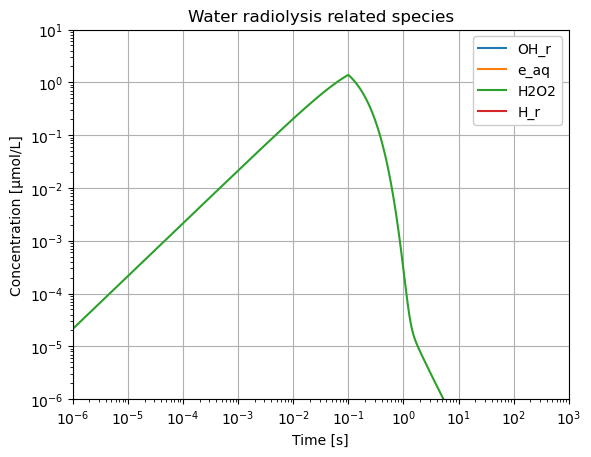

In [21]:
G_species = ["OH_r", "e_aq", "H2O2", "H_r"]
fig, ax = plt.subplots()
for label in G_species:
    ax.plot(df.index, df[label], label=label, marker="")

ax.set_ylim(bottom=1e-6, top=10)
ax.set_xlim([1e-6, RIGHT_LIMIT])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Concentration [µmol/L]")
ax.legend(fancybox=True, framealpha=1)
ax.set_title("Water radiolysis related species")
ax.grid()

#### Biology related species

In [ ]:
G_species = ["ROO_r", "R_r"]
fig, ax = plt.subplots()
for label in G_species:
    ax.plot(df.index, df[label], label=label, marker="")

ax.set_ylim(bottom=1e-6, top=100)
ax.set_xlim([1e-6, RIGHT_LIMIT])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Concentration [µmol/L]")
ax.legend(fancybox=True, framealpha=1)
ax.set_title("Biology related species")
ax.grid()

#### O2

In [ ]:
G_species = ["O2"]
fig, ax = plt.subplots()
for label in G_species:
    ax.plot(df.index, df[label], label=label, marker="")

ax.set_ylim(bottom=40, top=52)
ax.set_xlim([1e-6, RIGHT_LIMIT])
ax.set_xscale("log")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Concentration [µmol/L]")
ax.set_title("Molecular Oxygen")
ax.grid()